# TCA cycle model
This model is based on the metabolic network presentet in "OpenFLUX" Lake-Ee Quek et al.. 
First the true data(MIDs) are computed with the flux-values given in figure 3 in the article. 
Then simulation data is made by adding noise to the true data. The simulated data is CLR transformed. 

The simulated data and the CLR transformed simulated data are used to estimated fluxes in the metabolic network. 
In the end the results from the estimated flux on simulated data are compared with the estimated flux from the CLR transformed simulated data. 

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
from tca_openflux import TCA_OpenFLux, objective_wssr, objective_clr_wssr, flux_vector, calc_ci
from emu_example import closure, clr_func, clr_inv_func

import optimistix
import matplotlib.pyplot as plt

from scipy import stats


In [2]:
# To ensure mass balances some fluxes are calculated (v_dep) based on the other fluxes (v_free)
v_all = ["v1", "v2", "v3", "v4", "v5", "v6", "v7", "v8", "v9", "v10", "v11", "v12", "v13", "v14", "v15", "v16", "v17", "v18", "v19", "v20"]
v_free = {"v8": 0.215, "v1": 1, "v19": 0.05, "v20": 0.03, "v16": 0.07, "v17": 0.23, "v18": 0.12, "v2": 0.201, "v9": 0.296}
v_dep = {k for k in v_all if k not in v_free}

In [3]:
# The free fluxes are split into fixed fluxes and parameters, where parameters are the one being estimated. 
fixed_keys = ["v1", "v16", "v17", "v18", "v19", "v20"]
fixed = {k: v_free[k] for k in fixed_keys}

parameters = {k: v for k, v in v_free.items() if k not in fixed_keys}

# We calculate the true data (MIDs)
true_data = TCA_OpenFLux(parameters=parameters, fixed=fixed)

# We get a vector of all fluxes in the network. 
v_full = flux_vector(parameters, fixed)

## Simulations

We simulate MIDs by first assuming normal distributions on the absolute abundance (the reads), and then close it to 1 to get the relative abundance. 

In [4]:
rng = np.random.default_rng(seed=1234)
key = jax.random.PRNGKey(1234)
sims = 1000

total_mol = 1e5
total_isos = jax.tree.map(lambda x: x * total_mol, true_data)
cv = 0.2
norm_sigma_cv = jax.tree.map(lambda x: x * cv, total_isos)

key, key_sim = jax.random.split(key)
# We assume the absolute abandance to be independent normal distributions. 
norm_sim = jax.tree.map(
    lambda mean, sigma: mean + sigma * jax.random.normal(key_sim, (sims, mean.shape[0])),
    total_isos,
    norm_sigma_cv,
)

In [5]:
# Simulated absolute abandance are closed to 1 to make relative abundance
iso_proportions = jax.tree.map(
    lambda mat: closure(mat),
    norm_sim,
)

# Check that all sum to 1
jax.tree.map(
    lambda x: jnp.all(jnp.isclose(jnp.sum(x, axis=-1), 1.0, rtol=1e-10, atol=1e-10)),
    iso_proportions
)

{'aspx_1234': Array(True, dtype=bool),
 'lysx_123456': Array(True, dtype=bool),
 'suc_1234': Array(True, dtype=bool),
 'valx_12345': Array(True, dtype=bool)}

In [6]:
# We calculate the mean of the relative abundances. 
mean_sim = jax.tree.map(
    lambda x: jnp.mean(x, axis=0),  # mean over isotopolouges
    iso_proportions
)
# and the standard deviation
std_sim = jax.tree.map(
    lambda x: jnp.std(x, axis=0),  # standard deviation over isotopolouges
    iso_proportions
)

# and compute a covariance matrix
D_sim = jax.tree.map(
    lambda x: jnp.diag(x), 
    std_sim
)

## Parameter estimation

In [7]:
# We specify the solver and initial parameters
solver = optimistix.BFGS(
    rtol=1e-12, atol=1e-12, verbose=frozenset({"step"})
)

init_params = {
    "v8": 1.0,
    "v2": 1,
    "v9": 1,
}

In [8]:
# 
result_optimistix = optimistix.minimise(objective_wssr, y0=init_params, args=(mean_sim, D_sim, fixed), solver=solver, max_steps=10000)

In [ ]:
ci_euclidean = calc_ci(result_optimistix)

{'v2': {'mean': Array(0.20240499, dtype=float64),
  'std_error': Array(0.10207766, dtype=float64),
  'lower': Array(0.00233646, dtype=float64),
  'upper': Array(0.40247352, dtype=float64)},
 'v8': {'mean': Array(0.22399349, dtype=float64),
  'std_error': Array(0.94859567, dtype=float64),
  'lower': Array(-1.63521987, dtype=float64),
  'upper': Array(2.08320685, dtype=float64)},
 'v9': {'mean': Array(0.30363819, dtype=float64),
  'std_error': Array(0.64257102, dtype=float64),
  'lower': Array(-0.95577786, dtype=float64),
  'upper': Array(1.56305425, dtype=float64)}}

## CLR transformed

In [10]:
iso_clr = jax.tree.map(
    lambda x: clr_func(x),
    iso_proportions
)

# Check that all sum to 0
jax.tree.map(
    lambda x: jnp.all(jnp.isclose(jnp.sum(x, axis=-1), 0.0, rtol=1e-10, atol=1e-10)),
    iso_clr
)

{'aspx_1234': Array(True, dtype=bool),
 'lysx_123456': Array(True, dtype=bool),
 'suc_1234': Array(True, dtype=bool),
 'valx_12345': Array(True, dtype=bool)}

In [11]:
mean_clr = jax.tree.map(
    lambda x: jnp.mean(x, axis=0),  # mean over bins
    iso_clr
)

std_clr = jax.tree.map(
    lambda x: jnp.std(x, axis=0),  # mean over isotopolouges
    iso_clr
)

D_clr = jax.tree.map(
    lambda x: jnp.diag(x), 
    std_clr
)

In [12]:
mean_clr_inv = jax.tree.map(
    lambda x: clr_inv_func(x),
    mean_clr
)

In [13]:
result_optimistix_clr  = optimistix.minimise(objective_clr_wssr, y0=init_params, args=(mean_clr, D_clr, fixed), solver=solver, max_steps=10000)

In [ ]:
ci_aitchison = calc_ci(result_optimistix_clr)

In [15]:
print(f"True parameters: ", parameters)
print(f"Euclidean estimated parameters: ", result_optimistix.value)
print(f"CLR transformed estimated parameters: ", result_optimistix_clr.value)

True parameters:  {'v8': 0.215, 'v2': 0.201, 'v9': 0.296}
Euclidean estimated parameters:  {'v2': Array(0.20240499, dtype=float64), 'v8': Array(0.22399349, dtype=float64), 'v9': Array(0.30363819, dtype=float64)}
CLR transformed estimated parameters:  {'v2': Array(0.20105222, dtype=float64), 'v8': Array(0.21283379, dtype=float64), 'v9': Array(0.29512406, dtype=float64)}


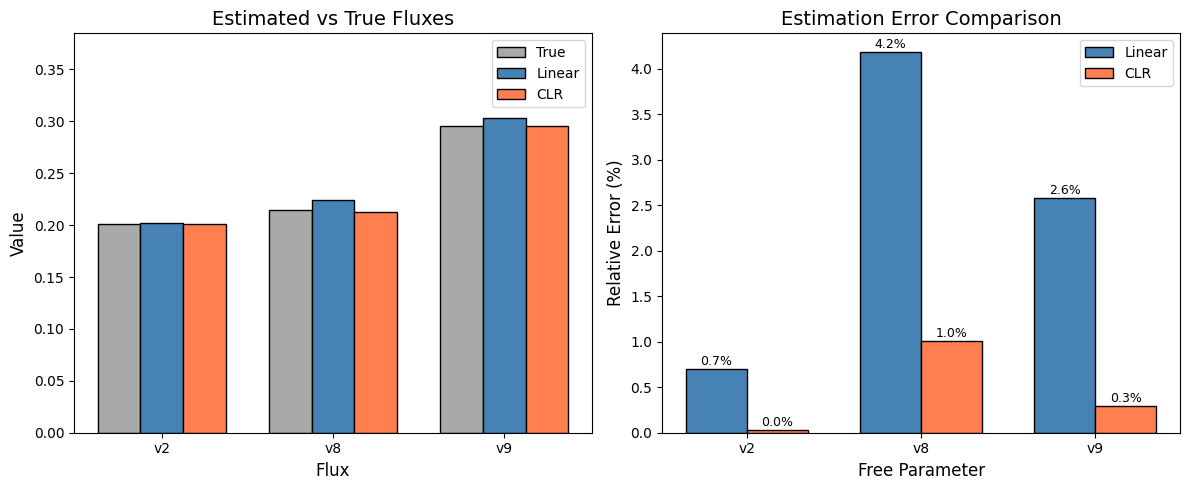

In [16]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Define the order we want to display
flux_labels = ["v2", "v8", "v9"]
x = np.arange(len(flux_labels))
width = 0.25

# 2. Extract values from dictionaries based on the labels
# This ensures that even if dict order changes, the bars stay aligned
v_true = np.array([parameters[k] for k in flux_labels])
v_est = np.array([result_optimistix.value[k] for k in flux_labels])
v_clr = np.array([result_optimistix_clr.value[k] for k in flux_labels])

# Left: Bar chart comparing all fluxes
bars1 = axes[0].bar(x - width, v_true, width, label='True', color='darkgray', edgecolor='black')
bars2 = axes[0].bar(x, v_est, width, label='Linear', color='steelblue', edgecolor='black')
bars3 = axes[0].bar(x + width, v_clr, width, label='CLR', color='coral', edgecolor='black')

axes[0].set_xlabel('Flux', fontsize=12)
axes[0].set_ylabel('Value', fontsize=12)
axes[0].set_title('Estimated vs True Fluxes', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels(flux_labels)
axes[0].legend(fontsize=10)
axes[0].set_ylim(0, max(v_true) * 1.3) # Added a bit more padding for labels

# Right: Relative error (%)
# Calculation now uses the NumPy arrays created above
rel_error_linear = 100 * np.abs(v_est - v_true) / v_true
rel_error_clr = 100 * np.abs(v_clr - v_true) / v_true

x2 = np.arange(len(flux_labels))
width2 = 0.35

bars4 = axes[1].bar(x2 - width2/2, rel_error_linear, width2, label='Linear', color='steelblue', edgecolor='black')
bars5 = axes[1].bar(x2 + width2/2, rel_error_clr, width2, label='CLR', color='coral', edgecolor='black')

axes[1].set_xlabel('Free Parameter', fontsize=12)
axes[1].set_ylabel('Relative Error (%)', fontsize=12)
axes[1].set_title('Estimation Error Comparison', fontsize=14)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(flux_labels)
axes[1].legend(fontsize=10)

# Add value labels on bars
def add_labels(bars, ax):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}%', 
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", 
                    ha='center', fontsize=9)

add_labels(bars4, axes[1])
add_labels(bars5, axes[1])

plt.tight_layout()
plt.show()